# GitHub Link: 
https://github.com/RhuanMendanha/CA01-Data-Visualisation-and-Communication-.git 

# Introduction:

The purpose of this notebook is to harness visualization to examine employment trends related to artificial intelligence (AI), data science, and software programming within the U.S. 

Data. The primary data source is the Occupational Employment and Wage Statistics (OEWS) “All data” file for May 2023 released by U.S. Bureau of Labor Statistics (2024), also known as BLS. This file contains 413,327 employment and wage estimates by occupation, geography (nation, state, and metropolitan area) and industry. The challenge section, besides making use of the national OEWS files of May 2014-March 2022 (BLS, 2015-2023) from the same page, focuses on trend analysis. 

Defining "AI employment." BLS uses the Standard Occupational Classification (SOC) which lacks a separate category for AI or machine learning engineers (Office of Management and Budget, 2018). As a result, AI jobs are studied through using proxy occupations.

| Family | SOC 2018 occupations used |
|---|---|
| **AI & Computing Research** | 15-1221 Computer & Information Research Scientists (the SOC group that includes AI/ML researchers) |
| **Data Science & Analytics** | 15-2051 Data Scientists, 15-2041 Statisticians, 15-2031 Operations Research Analysts, 15-2021 Mathematicians, 15-1243 Database Architects |
| **Software Development** | 15-1252 Software Developers, 15-1253 Software QA Analysts & Testers, 15-1251 Computer Programmers, 15-1254 Web Developers |

All families use the same color for all charts (blue, orange, aqua - a color-blind safe color set) to allow the reader to follow it in the notebook.

Running instructions: You need to download oesm23all.zip and oesm14nat.zip and oesm22nat.zip from https://www.bls.gov/oes/tables.htm and save these zip files (don’t extract them) to a folder called data/ which needs to be next to this notebook.

## 2. Setup
Libraries: **pandas** for data handling (McKinney, 2010), **matplotlib** (Hunter, 2007) and **seaborn** (Waskom, 2021) for the visualisations.

In [6]:
import zipfile, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# A consistent visual style for every chart in the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10,
})

# Colour-blind-safe categorical colours, one fixed colour per occupation family
FAMILY_COLOURS = {
    "AI & Computing Research": "#2a78d6",   # blue
    "Data Science & Analytics": "#eb6834",  # orange
    "Software Development": "#1baf7a",      # aqua
}
GREY = "#b9b8b3"

DATA_DIR = Path("data")   # put the BLS zip files here (they are NOT submitted with the notebook)
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 3.0.3


## 3. Loading the May 2023 data
The Excel file is read directly from inside the zip, so no manual unzipping is needed (loading takes 1–2 minutes because the file is large).

In [8]:
def read_excel_from_zip(zip_path, pattern):
    """Read the first .xlsx inside a BLS zip whose name matches `pattern` (no manual unzipping needed)."""
    with zipfile.ZipFile(zip_path) as z:
        member = next(n for n in z.namelist() if re.search(pattern, n, re.I))
        with z.open(member) as f:
            return pd.read_excel(f)

raw = read_excel_from_zip(DATA_DIR / "oesm23all.zip", r"all_data_M_2023\.xlsx$")
print(raw.shape)
raw.head(3)

(413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


## 4. Cleaning and selecting the data

The Bureau of Labor Statistics applies the following notations in its tables: * and ** denote that information is not provided, and # indicates that the salary is above $239,200. The notation of # is interpreted as 239,200, while */** indicates a void.

The analysis prefers the rows of the data indicating the domestic level, any industry, any ownership (AREA_TYPE = 1, I_GROUP = "cross-industry", OWN_CODE = 1235), and thus prevents double-counting of jobs within the same sector.

In [9]:
# BLS uses special symbols instead of numbers:
#   '*'  = wage estimate not available,  '**' = employment estimate not available,
#   '#'  = wage is >= $115.00/hour or $239,200/year (top-coded)
NUM_COLS = ["TOT_EMP", "EMP_PRSE", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL", "PCT_RPT",
            "H_MEAN", "A_MEAN", "MEAN_PRSE", "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

df = raw.copy()
for col in NUM_COLS:
    s = df[col].astype(str).str.strip()
    if col.startswith("A_"):
        s = s.replace("#", "239200")          # top-coded annual wages -> use the cap (a lower bound)
    df[col] = pd.to_numeric(s.replace({"*": np.nan, "**": np.nan, "~": np.nan}), errors="coerce")

# Occupations used as proxies for AI, Data Science and Software Development (SOC 2018 codes)
OCCUPATIONS = {
    "15-1221": ("Computer & Information Research Scientists", "AI & Computing Research"),
    "15-2051": ("Data Scientists",                            "Data Science & Analytics"),
    "15-2041": ("Statisticians",                              "Data Science & Analytics"),
    "15-2031": ("Operations Research Analysts",               "Data Science & Analytics"),
    "15-2021": ("Mathematicians",                             "Data Science & Analytics"),
    "15-1243": ("Database Architects",                        "Data Science & Analytics"),
    "15-1252": ("Software Developers",                        "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",             "Software Development"),
    "15-1251": ("Computer Programmers",                       "Software Development"),
    "15-1254": ("Web Developers",                             "Software Development"),
}
occ_map = pd.DataFrame.from_dict(OCCUPATIONS, orient="index", columns=["OCC", "FAMILY"])
occ_map.index.name = "OCC_CODE"

# National, all-industry, all-ownership rows
national = df[(df.AREA_TYPE == 1) & (df.I_GROUP == "cross-industry") & (df.OWN_CODE == 1235)]
ai = (national[national.OCC_CODE.isin(OCCUPATIONS)]
      .merge(occ_map, left_on="OCC_CODE", right_index=True))
ai[["OCC_CODE", "OCC", "FAMILY", "TOT_EMP", "A_MEAN", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,OCC_CODE,OCC,FAMILY,TOT_EMP,A_MEAN,A_MEDIAN
149,15-1252,Software Developers,Software Development,1656880.0,138110.0,132270.0
150,15-1253,Software QA Analysts & Testers,Software Development,203040.0,108460.0,101800.0
165,15-2051,Data Scientists,Data Science & Analytics,192710.0,119040.0,108020.0
148,15-1251,Computer Programmers,Software Development,120370.0,107750.0,99700.0
161,15-2031,Operations Research Analysts,Data Science & Analytics,117880.0,95600.0,83640.0
151,15-1254,Web Developers,Software Development,85350.0,95570.0,84960.0
145,15-1243,Database Architects,Data Science & Analytics,59920.0,137030.0,134700.0
138,15-1221,Computer & Information Research Scientists,AI & Computing Research,35210.0,157160.0,145080.0
163,15-2041,Statisticians,Data Science & Analytics,29950.0,109190.0,104110.0
159,15-2021,Mathematicians,Data Science & Analytics,2220.0,119770.0,116440.0


## Visualisation 1 – Horizontal bar chart: how many people work in each occupation?

Objective: comparison - to assess the size of various AI, data, and software jobs.

Why a horizontal bar chart: this specific diagram is used since there is one categorical variable (the occupation) and one quantitative variable (the employment). The bar length is the best visual representation for comparison of sizes, and the horizontal bars are optimal for long names of the occupations. The Software Developer occupation has approximately 1.66 million job listings, therefore it is roughly 750 times bigger than the job of a Mathematician (2,220).

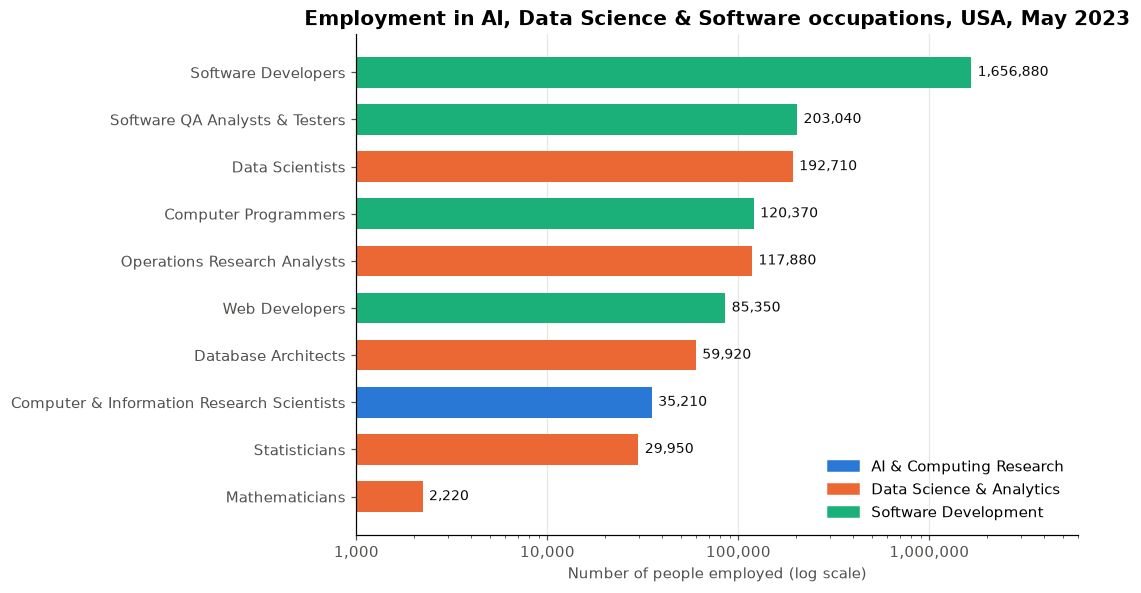

In [10]:
d = ai.sort_values("TOT_EMP")
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(d.OCC, d.TOT_EMP, color=d.FAMILY.map(FAMILY_COLOURS), height=0.65)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
for b, v in zip(bars, d.TOT_EMP):
    ax.text(v * 1.08, b.get_y() + b.get_height() / 2, f"{v:,.0f}", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(1_000, 6_000_000)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of people employed (log scale)")
ax.set_title("Employment in AI, Data Science & Software occupations, USA, May 2023")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOURS.values()]
ax.legend(handles, FAMILY_COLOURS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

### Here are my personal observations regarding the employment of AI:

The major employment contributors are software developers with the number of work positions being 1,656,880. This number takes up around two third of the number of working positions across 10 occupations (2.5 million jobs).
Data scientists work in the largest number as compared with other types of occupations in the sector (that is, 192,710). The number of data scientists exceeds the number of computer programmers (120,370) and operations research analysts (117,880). It is also more than six times bigger than the number of statisticians.
Computer and information research scientists hold the closest position to AI research. However, the number of their jobs in this field is significantly low (35,210). AI is evidently more of a research niche. Most activities in the field are performed by software developers and other people working in Data Science.

## Visualisation 2 – Donut chart: how is the workforce composed?

Aim: pie chart (part-to-whole) – what proportion of the total workforce in AI/data/software belongs to each family, and what is the total workforce in terms of the whole US workforce.

Reason for choosing pie chart: there are only three categories, which makes the use of a pie chart especially suitable. A pie chart has a hole in the middle that allows to put the total amount of jobs (2.50M) and the percentage of the total amount of jobs in the USA directly into the centre.

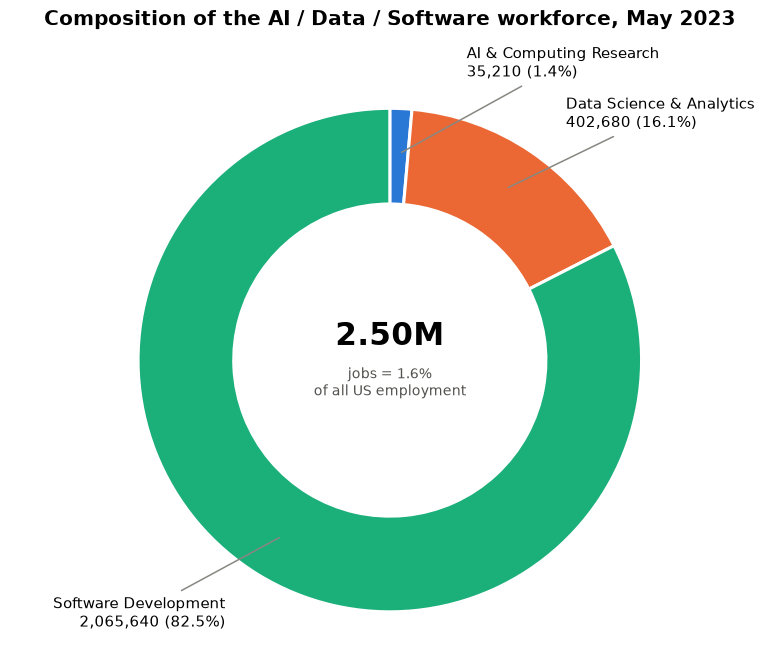

Total US employment: 151,853,870


In [11]:
fam = ai.groupby("FAMILY").TOT_EMP.sum().reindex(FAMILY_COLOURS.keys())
total_us = national.loc[national.OCC_CODE == "00-0000", "TOT_EMP"].iloc[0]

fig, ax = plt.subplots(figsize=(7.5, 6))
wedges, _ = ax.pie(fam, colors=fam.index.map(FAMILY_COLOURS), startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2))
for w, (name, val) in zip(wedges, fam.items()):
    ang = np.deg2rad((w.theta2 + w.theta1) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax.annotate(f"{name}\n{val:,.0f} ({val / fam.sum():.1%})", xy=(0.82 * x, 0.82 * y), xytext=(1.25 * x + (0.25 if val / fam.sum() < 0.05 else 0), 1.18 * y),
                ha="left" if x > 0 else "right", va="center", fontsize=10,
                arrowprops=dict(arrowstyle="-", color="#898781"))
ax.text(0, 0.06, f"{fam.sum() / 1e6:.2f}M", ha="center", fontsize=20, fontweight="bold")
ax.text(0, -0.14, f"jobs = {fam.sum() / total_us:.1%}\nof all US employment", ha="center", fontsize=9, color="#52514e")
ax.set_title("Composition of the AI / Data / Software workforce, May 2023", pad=38)
ax.axis("equal"); plt.tight_layout(); plt.show()
print(f"Total US employment: {total_us:,.0f}")

### What I have learn about AI Employment:

The data reveals that the field of Software Development makes up the largest part of employment in Artificial Intelligence consisting of 82.5% or more than 2 million people. The other sectors are Data Science and Analytics (16.1% or more than 400,000 jobs) and AI and Computing research (just 1.4%, or 35,000 jobs). The whole group of ten professions represents just 1.6% of the total number of jobs in the country which is 151.9 million. While AI as a field appears to be quite popular in the news, it represents just a tiny fraction of job opportunities in the country as of May 2023.

## Visualisation 3 – Box plot: what is the amount of salary for various jobs and the variability in salary?

Aim: distribution – assessing not only the average (median) salary but also the span of salaries for every occupation.

Reason for using a box plot: the wage is a variable of continuous nature and average alone makes the wage distributions look too equal. The OEWS data set gives the 10, 25, 50, 75, 90 percentiles, which correspond to the box plot. The box plot is useful for comparing numerous distributions at once.

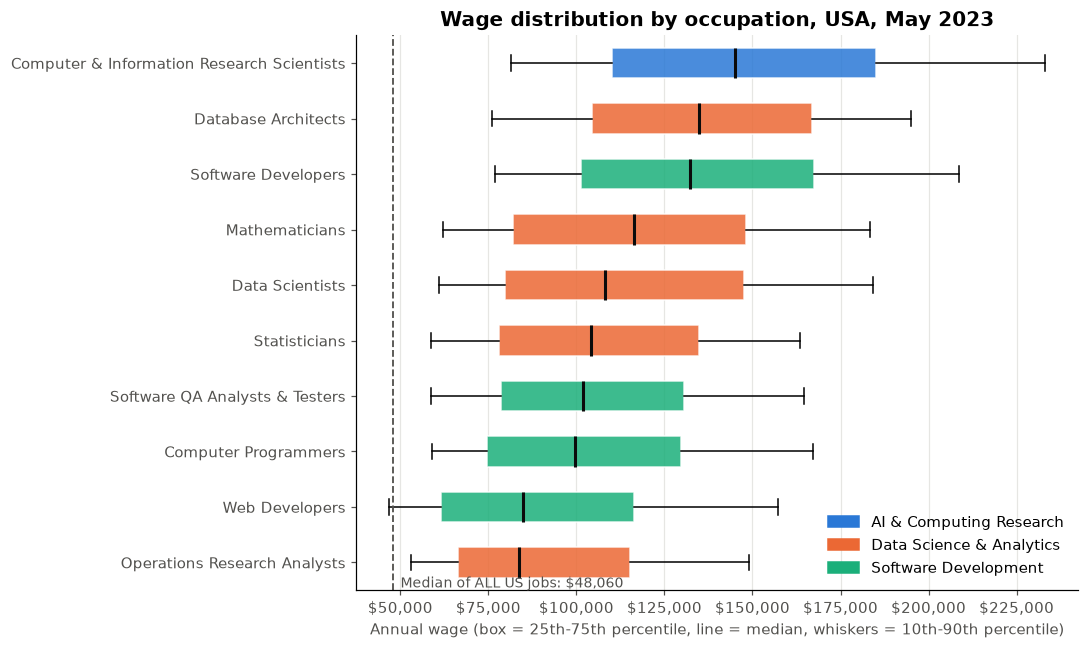

In [12]:
all_median = national.loc[national.OCC_CODE == "00-0000", "A_MEDIAN"].iloc[0]
d = ai.sort_values("A_MEDIAN")
stats = [dict(label=r.OCC, whislo=r.A_PCT10, q1=r.A_PCT25, med=r.A_MEDIAN, q3=r.A_PCT75, whishi=r.A_PCT90, fliers=[])
         for r in d.itertuples()]

fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.bxp(stats, orientation="horizontal", patch_artist=True, showfliers=False, widths=0.55,
            medianprops=dict(color="#0b0b0b", linewidth=2))
for patch, f in zip(bp["boxes"], d.FAMILY):
    patch.set_facecolor(FAMILY_COLOURS[f]); patch.set_alpha(0.85); patch.set_edgecolor("white")
ax.axvline(all_median, color="#52514e", ls="--", lw=1.2)
ax.text(all_median + 2_000, 0.55, f"Median of ALL US jobs: ${all_median:,.0f}", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Annual wage (box = 25th-75th percentile, line = median, whiskers = 10th-90th percentile)")
ax.set_title("Wage distribution by occupation, USA, May 2023")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOURS.values()]
ax.legend(handles, FAMILY_COLOURS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

All the jobs listed here pay well above the national median salary of USD 48,060. Even the lowest-paid job, Operations Research Analyst, earns 1.7 times the national median.

Computer and Information Research Scientist has the highest median salary, USD 145,080, as well as the highest salary potential, with the top 10% earning USD 233,110 or more.

Software Developer (USD 132,270) and Database Architect (USD 134,700) come next. Data Scientists have a median salary of USD 108,020, but salaries vary considerably, with professionals at the 90th percentile earning USD 184,090.